# ResNet-50 · ResNet-101 · ResNet-152 — Uncertainty-Aware Lung Cancer Classification
## IQ-OTH/NCCD Dataset · MC Dropout · XAI Spatial Correlation

This notebook extends the standard ResNet comparative study with the same
**uncertainty quantification and XAI trustworthiness analysis** framework used
in the MobileNet V1/V2/V3-Large companion notebook, so results are directly
comparable across the two model families.

### Contributions (identical methodology to the MobileNet notebook)

| Component | Description |
|-----------|-------------|
| **MC Dropout Inference** | Dropout kept active at test-time; T=50 stochastic forward passes per sample |
| **Predictive Entropy** | `H = -Σ p̄ log(p̄)` measures total output uncertainty per sample |
| **Mutual Information** | `MI = H - E[H(y\|x,w)]` isolates epistemic (model) uncertainty |
| **Saliency Localization** | Spatial concentration of each XAI map quantified via Gini coefficient + mass-in-peak ratio |
| **Uncertainty–XAI Correlation** | Spearman ρ between per-sample entropy and saliency diffuseness across all 5 XAI methods |
| **Cross-Model Comparison** | Correlation analysis repeated for ResNet-50/101/152 |

**Dataset classes:** Benign cases · Malignant cases · Normal cases

**Models:** ResNet-50 · ResNet-101 · ResNet-152 (all ImageNet-pretrained, fine-tuned)

**Evaluation stack (same as MobileNet notebook):**
- Training history, confusion matrix, ROC/PR curves, Decision Curve Analysis
- 5-method XAI panel: Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM
- MC Dropout uncertainty distributions + calibration reliability diagrams + Brier score
- Grad-CAM stability under Gaussian noise
- Uncertainty–XAI Spearman correlation, per-model and cross-model heatmaps
- Composite ranking score and CSV export

> **Runtime:** Set `Runtime → Change Runtime Type → T4 GPU` before running.
> ResNet-101 and ResNet-152 are deeper than the MobileNets, so training and the
> T=50 MC Dropout passes will take noticeably longer. Reduce `BATCH_SIZE` to 8
> in Cell 4 if you hit an out-of-memory error, and reduce `MC_T` / `MC_SAMPLE_N`
> if a single model's uncertainty analysis is taking too long on the free tier.


In [1]:
# ==========================================
# CELL 1: MOUNT GOOGLE DRIVE
# ==========================================
from google.colab import drive
drive.mount('/content/drive')

# --- UPDATE THIS PATH TO MATCH YOUR DRIVE LOCATION ---
directory  = '/content/drive/My Drive/Kaggle/IQ-OTH-NCCD/IQ-OTHNCCD-dataset/'
categories = ['Bengin cases', 'Malignant cases', 'Normal cases']


Mounted at /content/drive


In [2]:
# ==========================================
# CELL 2: IMPORT ALL LIBRARIES
# ==========================================
import os
import time
import random
import warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from collections import Counter

import pandas as pd
from scipy import stats
from scipy.stats import spearmanr, pearsonr

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, precision_recall_curve,
    average_precision_score, brier_score_loss
)
from sklearn.preprocessing import label_binarize
from sklearn.calibration import calibration_curve
from sklearn.utils import class_weight

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks, regularizers
from tensorflow.keras.applications import ResNet50, ResNet101, ResNet152
from tensorflow.keras.applications.resnet import preprocess_input as resnet_preprocess

warnings.filterwarnings('ignore')

# GPU memory growth (prevents TF from grabbing all GPU memory at once)
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print(f"TensorFlow version : {tf.__version__}")
print(f"GPUs available     : {len(gpus)}")
print(f"GPU name           : {gpus[0].name if gpus else 'No GPU — switch Runtime to GPU!'}")


TensorFlow version : 2.20.0
GPUs available     : 1
GPU name           : /physical_device:GPU:0


In [3]:
# ==========================================
# CELL 3: MODEL CONFIGURATION TABLE
#
# Fields:
#   model_key        : short identifier string
#   model_name       : display name
#   img_size         : input resolution (all ResNets use 224)
#   source           : 'keras' (built-in ImageNet-pretrained backbone)
#   keras_class      : Keras application class
#   freeze_n         : number of early backbone layers frozen during fine-tuning
#   last_conv_name   : layer name queried by all XAI methods
#   base_layer_name  : name of the wrapped backbone sub-model (used by the
#                      XAI extractor to locate the feature-map layers)
# ==========================================

MODEL_CONFIGS = [
    {
        'model_key'      : 'resnet50',
        'model_name'     : 'ResNet-50',
        'img_size'       : 224,
        'source'         : 'keras',
        'keras_class'    : ResNet50,
        'freeze_n'       : 80,
        'last_conv_name' : 'conv5_block3_out',
        'base_layer_name': 'resnet50',
    },
    {
        'model_key'      : 'resnet101',
        'model_name'     : 'ResNet-101',
        'img_size'       : 224,
        'source'         : 'keras',
        'keras_class'    : ResNet101,
        'freeze_n'       : 120,
        'last_conv_name' : 'conv5_block3_out',
        'base_layer_name': 'resnet101',
    },
    {
        'model_key'      : 'resnet152',
        'model_name'     : 'ResNet-152',
        'img_size'       : 224,
        'source'         : 'keras',
        'keras_class'    : ResNet152,
        'freeze_n'       : 150,
        'last_conv_name' : 'conv5_block3_out',
        'base_layer_name': 'resnet152',
    },
]

print("Model Configuration")
print("-" * 60)
print(f"{'Model':<28} {'Input':>7} {'Source':>8}")
print("-" * 60)
for cfg in MODEL_CONFIGS:
    print(f"{cfg['model_name']:<28} {str(cfg['img_size'])+'x'+str(cfg['img_size']):>7} {cfg['source']:>8}")
print("-" * 60)


Model Configuration
------------------------------------------------------------
Model                          Input   Source
------------------------------------------------------------
ResNet-50                    224x224    keras
ResNet-101                   224x224    keras
ResNet-152                   224x224    keras
------------------------------------------------------------


In [4]:
# ==========================================
# CELL 4: GLOBAL HYPERPARAMETERS
# ==========================================
BATCH_SIZE     = 16   # Reduce to 8 if you get an out-of-memory error
EPOCHS         = 50   # EarlyStopping will usually terminate well before this
VAL_SPLIT      = 0.1
TEST_SIZE      = 0.2
RANDOM_SEED    = 42
LEARNING_RATE  = 1e-3
DROPOUT_RATE   = 0.4
DENSE_UNITS    = 128
NUM_CLASSES    = 3

# MC Dropout parameters
MC_T           = 50    # Number of stochastic forward passes
MC_SAMPLE_N    = 100   # Number of test images to run the full MC+XAI pipeline on
                       # (the full test set is still used for accuracy/AUC metrics)
                       # Tip: lower MC_T / MC_SAMPLE_N if ResNet-101/152 are too
                       # slow to analyse on the Colab free tier.

print(f"MC Dropout passes per sample : {MC_T}")
print(f"MC+XAI analysis sample size  : {MC_SAMPLE_N}")


MC Dropout passes per sample : 50
MC+XAI analysis sample size  : 100


In [5]:
# ==========================================
# CELL 5: DATA LOADING
#
# All three ResNet variants use 224x224 input and the
# same ImageNet-style preprocessing (channel-wise mean
# subtraction via resnet_preprocess), so the data only
# needs to be loaded once and is shared across all models.
# ==========================================

def load_data(img_size=224):
    """
    Loads and preprocesses the IQ-OTH/NCCD dataset.
    Applies resnet_preprocess (subtracts ImageNet mean per channel).
    Returns X_train, X_test, y_train, y_test, class_weights_dict.
    """
    data = []
    for i, category in enumerate(categories):
        path = os.path.join(directory, category)
        for file in os.listdir(path):
            try:
                filepath = os.path.join(path, file)
                img = cv2.imread(filepath)
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img = cv2.resize(img, (img_size, img_size))
                img = resnet_preprocess(img.astype(np.float32))
                data.append([img, i])
            except Exception:
                pass

    random.seed(RANDOM_SEED)
    random.shuffle(data)

    X = np.array([d[0] for d in data])
    y = np.array([d[1] for d in data])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y
    )

    weights = class_weight.compute_class_weight(
        'balanced', classes=np.unique(y_train), y=y_train
    )
    class_weights_dict = dict(enumerate(weights))

    print(f"  Loaded {len(X)} images at {img_size}x{img_size}")
    print(f"  Train: {len(X_train)}  |  Test: {len(X_test)}")
    print(f"  Class distribution (train): {dict(Counter(y_train))}")
    return X_train, X_test, y_train, y_test, class_weights_dict


print("Loading dataset...")
X_train, X_test, y_train, y_test, class_weights_dict = load_data(img_size=224)
print("Dataset ready.")


Loading dataset...
  Loaded 1097 images at 224x224
  Train: 877  |  Test: 220
  Class distribution (train): {np.int64(1): 448, np.int64(2): 333, np.int64(0): 96}
Dataset ready.


In [6]:
# ==========================================
# CELL 6: MODEL BUILDERS WITH MC DROPOUT
#
# Key design: Dropout is placed BEFORE the final
# Dense layers, exactly as in the MobileNet notebook.
# During MC inference we call model(x, training=True)
# to keep dropout active and sample T different predictions.
#
# NOTE: this uses the Keras *functional* API (Input -> ... -> Model)
# rather than Sequential, so every head layer has an explicit name
# ('gap', 'head_bn', 'mc_dropout', 'head_dense', 'predictions').
# The XAI code in Cell 8 relies on these exact names to rebuild the
# model up to and after the last conv layer.
# ==========================================

def build_keras_resnet_mc(keras_class, img_size, freeze_n):
    """
    Builds a Keras ResNet (50/101/152) with an MC-Dropout-ready head.
    The Dropout layer is named 'mc_dropout' for easy identification.
    """
    base = keras_class(
        weights='imagenet', include_top=False,
        input_shape=(img_size, img_size, 3)
    )
    base.trainable = True
    for layer in base.layers[:freeze_n]:
        layer.trainable = False

    inp   = layers.Input(shape=(img_size, img_size, 3))
    x     = base(inp, training=False)   # BN in inference mode during fine-tune
    x     = layers.GlobalAveragePooling2D(name='gap')(x)
    x     = layers.BatchNormalization(name='head_bn')(x)
    x     = layers.Dropout(DROPOUT_RATE, name='mc_dropout')(x)  # MC target layer
    x     = layers.Dense(DENSE_UNITS, activation='relu',
                          kernel_regularizer=regularizers.l2(1e-4),
                          name='head_dense')(x)
    out   = layers.Dense(NUM_CLASSES, activation='softmax',
                          name='predictions')(x)
    return models.Model(inp, out)


def build_model(cfg):
    return build_keras_resnet_mc(
        cfg['keras_class'], cfg['img_size'], cfg['freeze_n']
    )


def get_callbacks():
    return [
        callbacks.EarlyStopping(
            monitor='val_loss', patience=8,
            restore_best_weights=True, verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.2, patience=4, verbose=1
        )
    ]

print("MC-Dropout-compatible model builders defined.")


MC-Dropout-compatible model builders defined.


In [7]:
# ==========================================
# CELL 7: MC DROPOUT INFERENCE ENGINE
#
# Theory (Gal & Ghahramani, 2016):
#   Run T stochastic forward passes with dropout ON.
#   Each pass samples a different dropout mask,
#   approximating a draw from the posterior
#   p(w | X, y) over network weights w.
#
# Outputs:
#   mean_probs   : (N, C) — predictive mean  p̄(y|x)
#   pred_entropy : (N,)   — total uncertainty H[p̄]
#   mutual_info  : (N,)   — epistemic uncertainty MI
#   all_samples  : (T, N, C) — raw MC samples
#
# Entropy formula:
#   H = -Σ_c  p̄_c * log(p̄_c + ε)
#
# Mutual Information (epistemic uncertainty):
#   MI = H[p̄] - (1/T) Σ_t H[p_t]
#   where p_t is the softmax output of the t-th pass.
# ==========================================

def mc_dropout_predict(model, X, T=MC_T, batch_size=BATCH_SIZE):
    """
    Runs T stochastic forward passes through the model
    with dropout ACTIVE (training=True).

    Parameters
    ----------
    model      : trained Keras model with mc_dropout layer
    X          : input array, shape (N, H, W, C)
    T          : number of Monte Carlo samples
    batch_size : mini-batch size for memory efficiency

    Returns
    -------
    mean_probs   : (N, C) predictive mean
    pred_entropy : (N,)   predictive entropy  H[p̄]
    mutual_info  : (N,)   mutual information  MI
    all_samples  : (T, N, C) all raw MC samples
    """
    N = len(X)
    all_preds = np.zeros((T, N, NUM_CLASSES), dtype=np.float32)

    for t in range(T):
        batch_preds = []
        for start in range(0, N, batch_size):
            batch = X[start:start + batch_size]
            # training=True keeps dropout active
            p = model(batch, training=True).numpy()
            batch_preds.append(p)
        all_preds[t] = np.concatenate(batch_preds, axis=0)

    # Predictive mean: average over T passes
    mean_probs = all_preds.mean(axis=0)           # (N, C)

    # Predictive entropy: H[p̄] = -Σ p̄ log(p̄)
    eps = 1e-8
    pred_entropy = -np.sum(
        mean_probs * np.log(mean_probs + eps), axis=1
    )                                              # (N,)

    # Per-sample entropy for each pass: H[p_t]
    per_pass_entropy = -np.sum(
        all_preds * np.log(all_preds + eps), axis=2
    )                                              # (T, N)

    # Mutual Information: MI = H[p̄] - E_t[H[p_t]]
    mutual_info = pred_entropy - per_pass_entropy.mean(axis=0)  # (N,)
    mutual_info = np.maximum(mutual_info, 0.0)    # numerical floor

    return mean_probs, pred_entropy, mutual_info, all_preds


def uncertainty_summary(pred_entropy, mutual_info, y_test, y_preds):
    """Prints a breakdown of uncertainty by correctness and class."""
    correct = (y_preds == y_test)
    print(f"\n  Predictive Entropy — Mean (all)     : {pred_entropy.mean():.4f}  ±{pred_entropy.std():.4f}")
    print(f"  Predictive Entropy — Correct preds  : {pred_entropy[correct].mean():.4f}")
    print(f"  Predictive Entropy — Wrong preds    : {pred_entropy[~correct].mean():.4f}")
    print(f"  Mutual Information — Mean (all)     : {mutual_info.mean():.4f}  ±{mutual_info.std():.4f}")
    print(f"  Mutual Information — Correct preds  : {mutual_info[correct].mean():.4f}")
    print(f"  Mutual Information — Wrong preds    : {mutual_info[~correct].mean():.4f}")
    for c, name in enumerate(categories):
        mask = y_test == c
        print(f"  Entropy [{name[:6]}...]  : {pred_entropy[mask].mean():.4f}")

print("MC Dropout inference engine defined.")

MC Dropout inference engine defined.


In [8]:
# ==========================================
# CELL 8: XAI FUNCTIONS
# All 5 methods: Grad-CAM, Grad-CAM++, Score-CAM,
# Eigen-CAM, Guided Grad-CAM.
# Compatible with the Keras-wrapper ResNet models
# built by Cell 6 (functional API, base ResNet wrapped as a sub-model).
# ==========================================

def _build_xai_extractors(model, cfg):
    """
    Returns (feat_model, pred_model) for XAI computation.
    feat_model : input → [last_conv_output, penultimate_output]
    pred_model : penultimate_output → class_probabilities
    """
    last_conv = cfg['last_conv_name']

    if cfg['base_layer_name'] is not None:
        # Keras-wrapped models (ResNet-50/101/152)
        # The functional API wraps the base inside a Model layer.
        # We must locate the base by its class name.
        base = None
        for lyr in model.layers:
            if hasattr(lyr, 'layers'):  # sub-model
                base = lyr
                break
        if base is None:
            raise ValueError(f"Cannot find sub-model in {cfg['model_name']}")

        # IMPORTANT: base.output is the RAW conv feature map (e.g. shape
        # (None, 7, 7, 1024)) -- it has NOT been pooled yet. The pred_head
        # sub-model below expects a pooled (None, 1024) vector as input
        # (that's what actually feeds head_bn -> mc_dropout -> head_dense
        # -> predictions in the real model). Feeding base.output directly
        # into pred_head caused the shape mismatch:
        #   "expected shape=(None, 1024), found shape=(1, 7, 7, 1024)"
        # Fix: apply a GlobalAveragePooling2D to base.output so `pen`
        # matches what the real 'gap' layer produces.
        pooled_pen = layers.GlobalAveragePooling2D(name='xai_gap')(base.output)
        feat_model = models.Model(
            inputs=base.input,
            outputs=[base.get_layer(last_conv).output, pooled_pen],
            name='feat_ext'
        )
        gap_shape = model.get_layer('gap').output.shape[1:]
        head_in   = layers.Input(shape=gap_shape)
        hx = head_in
        for lyr in model.layers:
            if lyr.name in ('head_bn', 'mc_dropout', 'head_dense', 'predictions'):
                hx = lyr(hx)
        pred_model = models.Model(inputs=head_in, outputs=hx, name='pred_head')

    else:
        # Fallback for a flat (non-wrapped) functional model, in case you
        # add a custom architecture later that doesn't wrap its backbone
        # in a sub-model. Not used by ResNet-50/101/152 above.
        feat_model = models.Model(
            inputs=model.input,
            outputs=[model.get_layer(last_conv).output,
                     model.get_layer('gap').output],
            name='feat_ext'
        )
        gap_shape = model.get_layer('gap').output.shape[1:]
        head_in   = layers.Input(shape=gap_shape)
        hx = head_in
        for lyr in model.layers:
            if lyr.name in ('head_bn', 'mc_dropout', 'head_dense', 'predictions'):
                hx = lyr(hx)
        pred_model = models.Model(inputs=head_in, outputs=hx, name='pred_head')

    return feat_model, pred_model


def _get_fmap_model(model, cfg):
    """Returns model that outputs only the last conv feature map."""
    last_conv = cfg['last_conv_name']
    if cfg['base_layer_name'] is not None:
        base = next(l for l in model.layers if hasattr(l, 'layers'))
        return models.Model(inputs=base.input,
                            outputs=base.get_layer(last_conv).output)
    return models.Model(inputs=model.input,
                        outputs=model.get_layer(last_conv).output)


# ---------- Grad-CAM ----------
def gradcam(img_array, model, cfg):
    fm, pm = _build_xai_extractors(model, cfg)
    with tf.GradientTape() as tape:
        conv_out, pen = fm(tf.cast(img_array, tf.float32))
        tape.watch(conv_out)
        preds = pm(pen)
        ci    = tf.argmax(preds[0])
        score = preds[:, ci]
    grads  = tape.gradient(score, conv_out)
    w      = tf.reduce_mean(grads, axis=(0, 1, 2))
    hm     = tf.squeeze(conv_out[0] @ w[..., tf.newaxis])
    hm     = tf.maximum(hm, 0) / (tf.reduce_max(hm) + 1e-7)
    return hm.numpy()


# ---------- Grad-CAM++ ----------
def gradcam_pp(img_array, model, cfg):
    fm, pm = _build_xai_extractors(model, cfg)
    with tf.GradientTape() as tape:
        conv_out, pen = fm(tf.cast(img_array, tf.float32))
        tape.watch(conv_out)
        preds = pm(pen)
        ci    = tf.argmax(preds[0])
        score = preds[:, ci]
    g  = tape.gradient(score, conv_out)
    d1 = tf.exp(score) * g
    d2 = tf.exp(score) * tf.pow(g, 2)
    d3 = tf.exp(score) * tf.pow(g, 3)
    gs = tf.reduce_sum(conv_out[0], axis=(0, 1)) + 1e-7
    al = d2[0] / (d2[0] * 2.0 + gs * d3[0] + 1e-7)
    w  = tf.reduce_sum(al * tf.maximum(d1[0], 0), axis=(0, 1))
    hm = tf.reduce_sum(w * conv_out[0], axis=-1)
    hm = tf.maximum(hm, 0) / (tf.reduce_max(hm) + 1e-7)
    return hm.numpy()


# ---------- Score-CAM ----------
def scorecam(img_array, model, cfg, img_size=224, n_channels=64):
    fmap_mdl = _get_fmap_model(model, cfg)
    features = fmap_mdl(img_array)
    up   = tf.image.resize(features, (img_size, img_size))
    mx   = tf.reduce_max(up, axis=(1, 2), keepdims=True)
    mn   = tf.reduce_min(up, axis=(1, 2), keepdims=True)
    norm = (up - mn) / (mx - mn + 1e-7)
    scores = []
    k = min(n_channels, features.shape[-1])
    for i in range(k):
        masked = img_array * norm[0, :, :, i:i+1]
        p = model.predict(masked, verbose=0)
        scores.append(p[0][np.argmax(p[0])])
    hm = np.dot(features.numpy()[0, :, :, :k], scores)
    hm = np.maximum(hm, 0)
    return hm / (np.max(hm) + 1e-7)


# ---------- Eigen-CAM ----------
def eigencam(img_array, model, cfg):
    fmap_mdl = _get_fmap_model(model, cfg)
    feat = fmap_mdl(img_array).numpy()[0]
    flat = feat.reshape(-1, feat.shape[-1])
    _, _, vh = np.linalg.svd(flat, full_matrices=False)
    hm = (flat @ vh[0]).reshape(feat.shape[0], feat.shape[1])
    hm = (hm - hm.min()) / (hm.max() - hm.min() + 1e-4)
    return hm


# ---------- Guided Grad-CAM ----------
def guided_gradcam(img_array, model, hm_gc, img_size=224):
    with tf.GradientTape() as tape:
        inp = tf.cast(img_array, tf.float32)
        tape.watch(inp)
        p  = model(inp, training=False)
        ci = tf.argmax(p[0])
        s  = p[:, ci]
    g   = tape.gradient(s, inp)[0].numpy()
    r   = cv2.resize(hm_gc.astype(np.float32), (img_size, img_size))
    ggc = g * r[..., np.newaxis]
    ggc = (ggc - ggc.min()) / (ggc.max() - ggc.min() + 1e-7)
    return ggc


# Registry for loop-based computation
XAI_METHODS = {
    'Grad-CAM'       : gradcam,
    'Grad-CAM++'     : gradcam_pp,
    'Score-CAM'      : scorecam,
    'Eigen-CAM'      : eigencam,
    'Guided Grad-CAM': None,   # handled separately (needs Grad-CAM result)
}

print("XAI functions defined (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM).")

XAI functions defined (Grad-CAM, Grad-CAM++, Score-CAM, Eigen-CAM, Guided Grad-CAM).


In [9]:
# ==========================================
# CELL 9: SALIENCY LOCALIZATION METRICS
#
# A saliency map is 'well-localized' if its
# activation mass is concentrated in a small
# focal region (high Gini, high mass-in-peak).
# A 'diffuse' map spreads activation broadly,
# which we expect to correlate with high
# predictive entropy — the key hypothesis.
#
# Metrics computed per saliency map:
#
#  1. Gini Coefficient (localization index)
#     G = 1 - Σ (2i/n - 1) * h_i / Σ h_i
#     where h sorted ascending, i = 1..n
#     G=1 → perfectly concentrated (focal)
#     G=0 → perfectly uniform (diffuse)
#     Diffuseness = 1 - G
#
#  2. Mass-in-Peak Ratio (MPR)
#     Fraction of total saliency mass in the
#     top-5% brightest pixels.
#     Low MPR → diffuse map.
#
#  3. Entropy of Saliency Distribution
#     H_s = -Σ p_s log(p_s)  (p_s = h/Σh)
#     High H_s → diffuse / disordered map.
#
#  4. Effective Mass Fraction (EMF)
#     Fraction of pixels contributing 80%
#     of total saliency. Low EMF → focal.
# ==========================================

def gini_coefficient(hm):
    """
    Gini coefficient of a 2-D saliency map.
    Returns float in [0,1]. Higher = more concentrated.
    """
    h = hm.flatten().astype(np.float64)
    h = np.abs(h)
    if h.sum() == 0:
        return 0.0
    h = np.sort(h)
    n = len(h)
    idx = np.arange(1, n + 1)
    return float((2 * (idx * h).sum() / (n * h.sum())) - (n + 1) / n)


def mass_in_peak_ratio(hm, top_frac=0.05):
    """
    Fraction of total saliency in the top `top_frac` of pixels.
    """
    h = hm.flatten()
    if h.sum() == 0:
        return 0.0
    thresh = np.percentile(h, (1 - top_frac) * 100)
    return float(h[h >= thresh].sum() / (h.sum() + 1e-8))


def saliency_entropy(hm):
    """
    Shannon entropy of the normalised saliency distribution.
    Higher = more diffuse.
    """
    h = hm.flatten().astype(np.float64)
    h = np.abs(h)
    s = h.sum()
    if s == 0:
        return 0.0
    p = h / s
    p = p[p > 0]
    return float(-np.sum(p * np.log(p)))


def effective_mass_fraction(hm, mass_frac=0.80):
    """
    Fraction of pixels needed to accumulate `mass_frac` of total saliency.
    Lower = more focal.
    """
    h = np.abs(hm.flatten())
    if h.sum() == 0:
        return 1.0
    h_sorted = np.sort(h)[::-1]
    cumsum   = np.cumsum(h_sorted)
    target   = mass_frac * h_sorted.sum()
    idx      = np.searchsorted(cumsum, target)
    return float((idx + 1) / len(h))


def compute_spatial_metrics(hm, img_size=224):
    """
    Upsamples hm to img_size x img_size and returns all 4 metrics.
    Returns dict with keys: gini, diffuseness, mpr, sal_entropy, emf
    """
    hm_up = cv2.resize(hm.astype(np.float32), (img_size, img_size))
    g = gini_coefficient(hm_up)
    return {
        'gini'       : g,
        'diffuseness': 1.0 - g,
        'mpr'        : mass_in_peak_ratio(hm_up),
        'sal_entropy': saliency_entropy(hm_up),
        'emf'        : effective_mass_fraction(hm_up),
    }

print("Saliency localization metrics defined (Gini, MPR, Saliency Entropy, EMF).")

Saliency localization metrics defined (Gini, MPR, Saliency Entropy, EMF).


In [10]:
# ==========================================
# CELL 10: UNCERTAINTY–XAI CORRELATION ANALYSIS
#
# For each model and each XAI method we:
#  1. Run MC Dropout to get per-sample entropy H
#  2. Compute all 5 XAI maps per sample
#  3. Extract spatial diffuseness metrics from each map
#  4. Compute Spearman ρ between H and diffuseness
#  5. Test statistical significance (p-value)
#
# Hypothesis (from TrustNet extended):
#   Samples with HIGH predictive entropy should
#   produce DIFFUSE (poorly localized) saliency maps
#   across all XAI methods — positive ρ expected.
# ==========================================

def run_uncertainty_xai_correlation(
        model, cfg, X_sample, y_sample, entropy_sample,
        img_size=224, verbose=True):
    """
    For `MC_SAMPLE_N` test images:
      - Computes all 5 XAI maps
      - Extracts spatial diffuseness metrics
      - Correlates with per-sample predictive entropy

    Returns
    -------
    corr_results : dict keyed by XAI method name,
                   each value is dict of {metric: (rho, pval)}
    spatial_df   : DataFrame with per-sample metrics
    """
    model_name = cfg['model_name']
    N = len(X_sample)

    # Storage: for each XAI method, collect per-sample spatial metrics
    xai_names = ['Grad-CAM', 'Grad-CAM++', 'Score-CAM',
                 'Eigen-CAM', 'Guided Grad-CAM']
    metric_names = ['diffuseness', 'sal_entropy', 'emf', 'mpr', 'gini']

    records = []  # one row per sample per XAI method

    for idx in range(N):
        img_arr = np.expand_dims(X_sample[idx], axis=0)

        if verbose and idx % 20 == 0:
            print(f"    Processing sample {idx+1}/{N}...")

        # --- Compute all XAI maps ---
        hm_dict = {}
        try:
            hm_gc         = gradcam(img_arr, model, cfg)
            hm_gcpp       = gradcam_pp(img_arr, model, cfg)
            hm_sc         = scorecam(img_arr, model, cfg, img_size)
            hm_eig        = eigencam(img_arr, model, cfg)
            hm_ggc_3ch    = guided_gradcam(img_arr, model, hm_gc, img_size)
            hm_ggc        = hm_ggc_3ch.mean(axis=-1)  # collapse to 2D
            hm_dict = {
                'Grad-CAM'       : hm_gc,
                'Grad-CAM++'     : hm_gcpp,
                'Score-CAM'      : hm_sc,
                'Eigen-CAM'      : hm_eig,
                'Guided Grad-CAM': hm_ggc,
            }
        except Exception as e:
            if verbose:
                print(f"    XAI failed for sample {idx}: {e}")
            continue

        # --- Compute spatial metrics for each XAI method ---
        for xai_name, hm in hm_dict.items():
            sm = compute_spatial_metrics(hm, img_size)
            records.append({
                'sample_idx'      : idx,
                'true_label'      : y_sample[idx],
                'pred_entropy'    : entropy_sample[idx],
                'xai_method'      : xai_name,
                **sm
            })

    spatial_df = pd.DataFrame(records)

    # Defensive guard: if every sample's XAI computation failed above,
    # `records` is empty and spatial_df has no columns at all -- indexing
    # spatial_df['xai_method'] would then raise KeyError. Bail out cleanly
    # instead so the caller gets an empty-but-valid result.
    if spatial_df.empty or 'xai_method' not in spatial_df.columns:
        print("  No successful XAI computations -- skipping correlation table.")
        return {}, spatial_df

    # --- Spearman correlation: entropy vs each spatial metric ---
    corr_results = {}
    print(f"\n  Uncertainty–XAI Correlation Table [{model_name}]")
    print(f"  {'XAI Method':<20} {'Diffuse ρ':>10} {'p-val':>8} "
          f"{'SalEntropy ρ':>13} {'p-val':>8} {'EMF ρ':>8} {'p-val':>8}")
    print("  " + "-"*85)

    for xai_name in xai_names:
        sub = spatial_df[spatial_df['xai_method'] == xai_name]
        if len(sub) < 5:
            continue
        H = sub['pred_entropy'].values
        corr_results[xai_name] = {}
        row_str = f"  {xai_name:<20}"
        for metric in metric_names:
            rho, pval = spearmanr(H, sub[metric].values)
            corr_results[xai_name][metric] = (rho, pval)
        # Print key metrics
        rd, pd_ = corr_results[xai_name]['diffuseness']
        rs, ps  = corr_results[xai_name]['sal_entropy']
        re, pe  = corr_results[xai_name]['emf']
        sig_d = '*' if pd_ < 0.05 else ' '
        sig_s = '*' if ps  < 0.05 else ' '
        sig_e = '*' if pe  < 0.05 else ' '
        print(f"  {xai_name:<20} {rd:>+9.3f}{sig_d} {pd_:>8.3f} "
              f"{rs:>+12.3f}{sig_s} {ps:>8.3f} {re:>+7.3f}{sig_e} {pe:>8.3f}")

    print("  * p < 0.05")
    return corr_results, spatial_df


print("Uncertainty–XAI correlation engine defined.")

Uncertainty–XAI correlation engine defined.


In [11]:
# ==========================================
# CELL 11: EVALUATION & VISUALISATION HELPERS
# ==========================================

def plot_training_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history.history['accuracy'],     label='Train Acc',  color='royalblue', ls='--')
    axes[0].plot(history.history['val_accuracy'], label='Val Acc',    color='navy')
    axes[0].set_title(f'{model_name}: Accuracy'); axes[0].set_xlabel('Epochs')
    axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(history.history['loss'],     label='Train Loss', color='tomato', ls='--')
    axes[1].plot(history.history['val_loss'], label='Val Loss',   color='darkred')
    axes[1].set_title(f'{model_name}: Loss'); axes[1].set_xlabel('Epochs')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.suptitle(f'{model_name} — Training History', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()


def plot_confusion_matrix(y_test, y_pred, model_name):
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=categories, yticklabels=categories)
    plt.title(f'Confusion Matrix: {model_name}', fontweight='bold')
    plt.ylabel('Actual'); plt.xlabel('Predicted')
    plt.tight_layout(); plt.show()


def plot_roc_pr_curves(y_test, y_probs, model_name):
    y_bin  = label_binarize(y_test, classes=[0, 1, 2])
    colors = ['royalblue', 'crimson', 'seagreen']
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for i, color in enumerate(colors):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_probs[:, i])
        axes[0].plot(fpr, tpr, color=color, lw=2,
                     label=f'{categories[i]} (AUC={auc(fpr,tpr):.3f})')
        prec, rec, _ = precision_recall_curve(y_bin[:, i], y_probs[:, i])
        ap = average_precision_score(y_bin[:, i], y_probs[:, i])
        axes[1].plot(rec, prec, color=color, lw=2,
                     label=f'{categories[i]} (AP={ap:.3f})')
    axes[0].plot([0,1],[0,1],'k--',alpha=0.4)
    axes[0].set_title(f'ROC: {model_name}', fontweight='bold')
    axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
    axes[0].legend(loc='lower right'); axes[0].grid(alpha=0.3)
    axes[1].set_title(f'Precision-Recall: {model_name}', fontweight='bold')
    axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
    axes[1].legend(loc='lower left'); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def plot_dca(y_test, y_probs, model_name):
    y_bin      = label_binarize(y_test, classes=[0, 1, 2])
    y_true_mal = y_bin[:, 1]; y_prob_mal = y_probs[:, 1]
    def nb(yt, yp, t):
        yhat = (yp >= t).astype(int)
        tp = np.sum((yhat==1)&(yt==1)); fp = np.sum((yhat==1)&(yt==0))
        n  = len(yt)
        return 0 if (n==0 or t>=1) else (tp/n) - (fp/n)*(t/(1-t))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    fpr, tpr, _ = roc_curve(y_true_mal, y_prob_mal)
    ax1.plot(fpr, tpr, color='navy', lw=2, label=f'Malignant (AUC={auc(fpr,tpr):.3f})')
    ax1.plot([0,1],[0,1],'k--',alpha=0.4)
    ax1.set_title(f'ROC — {model_name}', fontweight='bold')
    ax1.set_xlabel('FPR'); ax1.set_ylabel('TPR')
    ax1.legend(loc='lower right'); ax1.grid(alpha=0.3)
    thresholds = np.linspace(0.01, 0.99, 100)
    prev = np.mean(y_true_mal)
    ax2.plot(thresholds, [nb(y_true_mal, y_prob_mal, t) for t in thresholds],
             color='navy', lw=2, label=model_name)
    ax2.plot(thresholds, [prev-(1-prev)*(t/(1-t)) for t in thresholds],
             'k--', alpha=0.4, label='Treat All')
    ax2.axhline(0, color='black', lw=1, label='Treat None')
    ax2.set_ylim([-0.05, prev+0.15])
    ax2.set_title(f'Decision Curve Analysis — {model_name}', fontweight='bold')
    ax2.set_xlabel('Threshold'); ax2.set_ylabel('Net Benefit')
    ax2.legend(loc='upper right'); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def measure_latency(model, X_test):
    t0 = time.time()
    model.predict(X_test, verbose=0)
    return (time.time() - t0) / len(X_test) * 1000


print("Evaluation helpers defined.")

Evaluation helpers defined.


In [12]:
# ==========================================
# CELL 12: UNCERTAINTY VISUALISATION HELPERS
# ==========================================

def plot_uncertainty_distribution(pred_entropy, mutual_info, y_test, y_preds,
                                    model_name, mean_probs=None):
    """
    Four-panel uncertainty analysis.

    Panel A : Entropy distribution split by ground-truth class.
    Panel B : Entropy histogram for correct vs incorrect predictions.
    Panel C : Scatter of predictive entropy vs mutual information
              (total vs epistemic uncertainty), coloured by true class.
    Panel D : Confidence histogram (max MC softmax probability)
              split by correct / incorrect — shows whether the model
              assigns lower confidence to wrong predictions.
              Falls back to a per-class mean-entropy bar chart when
              mean_probs is not supplied.

    Parameters
    ----------
    pred_entropy : (N,) predictive entropy  H[p-bar]
    mutual_info  : (N,) mutual information  MI
    y_test       : (N,) true integer labels
    y_preds      : (N,) predicted integer labels (argmax of MC mean)
    model_name   : str
    mean_probs   : (N, C) MC mean softmax probabilities  **in [0,1]**
                   Pass `mean_probs` from mc_dropout_predict() so that
                   Panel D uses valid probability values.
    """
    correct = (y_preds == y_test)
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f'{model_name} — MC Dropout Uncertainty Analysis (T={MC_T})',
                 fontsize=13, fontweight='bold')

    # ---- Panel A: Entropy by class ----
    cls_colors = ['#3498db', '#e74c3c', '#2ecc71']
    for c, (name, col) in enumerate(zip(categories, cls_colors)):
        axes[0].hist(pred_entropy[y_test == c], bins=20, alpha=0.65,
                     label=name[:10], color=col, edgecolor='white')
    axes[0].set_xlabel('Predictive Entropy H[p̄]')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Entropy by Class')
    axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)

    # ---- Panel B: Entropy — correct vs incorrect ----
    axes[1].hist(pred_entropy[correct],  bins=20, alpha=0.7, color='seagreen',
                 label='Correct', edgecolor='white')
    axes[1].hist(pred_entropy[~correct], bins=20, alpha=0.7, color='crimson',
                 label='Incorrect', edgecolor='white')
    axes[1].set_xlabel('Predictive Entropy H[p̄]')
    axes[1].set_ylabel('Count')
    axes[1].set_title('Entropy: Correct vs Incorrect')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    # ---- Panel C: Entropy vs Mutual Information scatter ----
    sc = axes[2].scatter(pred_entropy, mutual_info,
                         c=y_test, cmap='viridis', alpha=0.6, s=18)
    axes[2].set_xlabel('Predictive Entropy H[p̄]')
    axes[2].set_ylabel('Mutual Information MI')
    axes[2].set_title('Entropy vs Epistemic Uncertainty')
    plt.colorbar(sc, ax=axes[2], label='True Class')
    axes[2].grid(alpha=0.3)

    # ---- Panel D: Confidence histogram OR per-class entropy bar ----
    if mean_probs is not None:
        # max_conf is guaranteed in [0,1] — safe to use as y_prob
        max_conf = mean_probs.max(axis=1)   # shape (N,)
        axes[3].hist(max_conf[correct],  bins=20, alpha=0.7, color='seagreen',
                     label='Correct', edgecolor='white')
        axes[3].hist(max_conf[~correct], bins=20, alpha=0.7, color='crimson',
                     label='Incorrect', edgecolor='white')
        axes[3].set_xlabel('Max MC Softmax Confidence')
        axes[3].set_ylabel('Count')
        axes[3].set_title('Confidence: Correct vs Incorrect')
        axes[3].legend(); axes[3].grid(alpha=0.3)
    else:
        # Fallback when mean_probs not available
        means = [pred_entropy[y_test == c].mean() for c in range(len(categories))]
        axes[3].bar(categories, means, color=cls_colors, alpha=0.8, edgecolor='white')
        axes[3].set_xlabel('Class'); axes[3].set_ylabel('Mean Entropy')
        axes[3].set_title('Mean Entropy per Class')
        axes[3].grid(axis='y', alpha=0.3)

    plt.tight_layout(); plt.show()


def plot_uncertainty_calibration(y_test, mean_probs, model_name):
    """Reliability diagram using MC mean probabilities (all 3 classes)."""
    y_bin = label_binarize(y_test, classes=[0, 1, 2])
    colors = ['royalblue', 'crimson', 'seagreen']
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f'{model_name} — Calibration Reliability Diagrams (MC Dropout)',
                 fontsize=12, fontweight='bold')
    for i, (name, col) in enumerate(zip(categories, colors)):
        try:
            fp, mp = calibration_curve(y_bin[:, i], mean_probs[:, i],
                                       n_bins=10, strategy='uniform')
            axes[i].plot([0,1],[0,1],'k--',alpha=0.4,label='Perfect')
            axes[i].plot(mp, fp, 'o-', color=col, lw=2, ms=6, label=model_name)
            axes[i].fill_between(mp, fp, mp, alpha=0.15, color=col)
            axes[i].set_title(f'{name[:15]}', fontweight='bold')
            axes[i].set_xlabel('Mean Predicted Prob.')
            axes[i].set_ylabel('Fraction of Positives')
            axes[i].legend(fontsize=8); axes[i].grid(alpha=0.3)
        except Exception:
            pass
    plt.tight_layout(); plt.show()


def plot_entropy_violin(entropy_dict):
    """Cross-model entropy distribution comparison as violin plot."""
    fig, ax = plt.subplots(figsize=(12, 5))
    data_list  = list(entropy_dict.values())
    model_list = list(entropy_dict.keys())
    vp = ax.violinplot(data_list, showmeans=True, showmedians=True)
    colors = ['#2980b9','#27ae60','#8e44ad','#e67e22']
    for pc, col in zip(vp['bodies'], colors):
        pc.set_facecolor(col); pc.set_alpha(0.7)
    ax.set_xticks(range(1, len(model_list)+1))
    ax.set_xticklabels(model_list, rotation=15, ha='right')
    ax.set_ylabel('Predictive Entropy H[p̄]')
    ax.set_title('Cross-Model Uncertainty Distribution (MC Dropout)',
                 fontsize=13, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()


def plot_xai_panel_with_uncertainty(
        model, cfg, X_test, y_test, entropy, sample_idx=5, img_size=224):
    """
    Extended XAI panel: 6 XAI maps + 1 uncertainty bar per sample.
    The title shows the sample's entropy and whether the map is
    classified as high/low uncertainty.
    """
    img_arr   = np.expand_dims(X_test[sample_idx], axis=0)
    disp      = X_test[sample_idx].copy()
    disp      = (disp - disp.min()) / (disp.max() - disp.min() + 1e-7)
    ent_val   = entropy[sample_idx]
    model_name= cfg['model_name']
    true_label= categories[y_test[sample_idx]]
    raw_pred  = model.predict(img_arr, verbose=0)
    pred_label= categories[np.argmax(raw_pred[0])]
    unc_tag   = 'HIGH-Uncertainty' if ent_val > np.median(entropy) else 'low-uncertainty'

    try:
        hm_gc   = gradcam(img_arr, model, cfg)
        hm_gcpp = gradcam_pp(img_arr, model, cfg)
        hm_sc   = scorecam(img_arr, model, cfg, img_size)
        hm_eig  = eigencam(img_arr, model, cfg)
        hm_ggc  = guided_gradcam(img_arr, model, hm_gc, img_size)

        fig = plt.figure(figsize=(28, 5))
        gs  = gridspec.GridSpec(1, 7, figure=fig, wspace=0.05)
        fig.suptitle(
            f'XAI+Uncertainty Panel — {model_name}  |  '
            f'True: {true_label}  |  Pred: {pred_label}  |  '
            f'H[p̄]={ent_val:.3f} [{unc_tag}]',
            fontsize=11, fontweight='bold'
        )

        panels = [
            ('Original CT',    disp,    None),
            ('Grad-CAM',       disp,    hm_gc),
            ('Grad-CAM++',     disp,    hm_gcpp),
            ('Score-CAM',      disp,    hm_sc),
            ('Eigen-CAM',      disp,    hm_eig),
            ('Guided GradCAM', hm_ggc,  None),
        ]

        for j, (title, bg, hm) in enumerate(panels):
            ax = fig.add_subplot(gs[j])
            ax.set_title(title, fontsize=8)
            ax.axis('off')
            ax.imshow(bg)
            if hm is not None:
                ax.imshow(cv2.resize(hm.astype(np.float32), (img_size, img_size)),
                          alpha=0.5, cmap='jet')

        # Entropy bar
        ax_ent = fig.add_subplot(gs[6])
        max_ent = np.log(NUM_CLASSES)
        bar_col = '#e74c3c' if ent_val > np.median(entropy) else '#2ecc71'
        ax_ent.barh(['H[p̄]'], [ent_val], color=bar_col, edgecolor='black')
        ax_ent.set_xlim(0, max_ent)
        ax_ent.axvline(np.median(entropy), color='navy', ls='--', lw=1.5,
                       label=f'Median={np.median(entropy):.2f}')
        ax_ent.set_xlabel('Entropy')
        ax_ent.set_title('Uncertainty', fontsize=8)
        ax_ent.legend(fontsize=7)
        plt.tight_layout(); plt.show()

    except Exception as e:
        print(f"  XAI+Uncertainty panel failed: {e}")


def plot_uncertainty_xai_scatter(spatial_df, corr_results, model_name):
    """
    For each XAI method: scatter plot of entropy vs diffuseness,
    with Spearman ρ annotated.
    """
    xai_names = ['Grad-CAM', 'Grad-CAM++', 'Score-CAM', 'Eigen-CAM', 'Guided Grad-CAM']
    colors = ['#2980b9','#e74c3c','#27ae60','#8e44ad','#e67e22']

    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    fig.suptitle(
        f'Predictive Entropy vs Saliency Diffuseness — {model_name}',
        fontsize=13, fontweight='bold'
    )

    for ax, xai_name, col in zip(axes, xai_names, colors):
        sub = spatial_df[spatial_df['xai_method'] == xai_name]
        if len(sub) == 0:
            ax.set_visible(False)
            continue
        ax.scatter(sub['pred_entropy'], sub['diffuseness'],
                   c=sub['true_label'], cmap='viridis',
                   alpha=0.7, s=25, edgecolors='none')
        # Trend line
        z = np.polyfit(sub['pred_entropy'], sub['diffuseness'], 1)
        xline = np.linspace(sub['pred_entropy'].min(), sub['pred_entropy'].max(), 50)
        ax.plot(xline, np.poly1d(z)(xline), color=col, lw=2, ls='--')

        if xai_name in corr_results:
            rho, pval = corr_results[xai_name]['diffuseness']
            sig = '**' if pval < 0.01 else ('*' if pval < 0.05 else 'ns')
            ax.set_title(f'{xai_name}\nρ={rho:+.3f} {sig}', fontsize=9)
        else:
            ax.set_title(xai_name, fontsize=9)
        ax.set_xlabel('Entropy H[p̄]', fontsize=8)
        ax.set_ylabel('Diffuseness (1-Gini)', fontsize=8)
        ax.grid(alpha=0.3)

    plt.tight_layout(); plt.show()


def plot_correlation_heatmap(all_model_corr, metric='diffuseness'):
    """
    Cross-model × XAI-method heatmap of Spearman ρ for one metric.
    """
    xai_names   = ['Grad-CAM', 'Grad-CAM++', 'Score-CAM', 'Eigen-CAM', 'Guided Grad-CAM']
    model_names = list(all_model_corr.keys())
    mat = np.zeros((len(model_names), len(xai_names)))
    mat_sig = np.full((len(model_names), len(xai_names)), '', dtype=object)

    for i, mn in enumerate(model_names):
        for j, xn in enumerate(xai_names):
            try:
                rho, pval = all_model_corr[mn][xn][metric]
                mat[i, j] = rho
                mat_sig[i, j] = '**' if pval < 0.01 else ('*' if pval < 0.05 else '')
            except Exception:
                mat[i, j] = np.nan

    annot = np.array([[f"{mat[i,j]:.2f}{mat_sig[i,j]}"
                       for j in range(len(xai_names))]
                      for i in range(len(model_names))])

    fig, ax = plt.subplots(figsize=(13, 5))
    sns.heatmap(mat, annot=annot, fmt='', cmap='RdBu_r',
                center=0, vmin=-1, vmax=1,
                xticklabels=xai_names, yticklabels=model_names,
                linewidths=0.5, ax=ax,
                annot_kws={'size': 10})
    ax.set_title(
        f'Spearman ρ: Predictive Entropy vs Saliency {metric.replace("_"," ").title()}\n'
        '(* p<0.05  ** p<0.01)',
        fontsize=12, fontweight='bold'
    )
    ax.set_xlabel('XAI Method', fontsize=11)
    ax.set_ylabel('Model', fontsize=11)
    plt.tight_layout(); plt.show()


def plot_stability(stability_dict):
    fig, ax = plt.subplots(figsize=(10, 4))
    model_names = list(stability_dict.keys())
    stab_vals   = list(stability_dict.values())
    ax.bar(model_names, stab_vals, color='#1abc9c', alpha=0.85, edgecolor='white')
    ax.set_ylim(0, 1.05)
    ax.set_title('Grad-CAM Explanation Stability (Pearson r)', fontweight='bold')
    ax.set_ylabel('Stability Score'); ax.grid(axis='y', alpha=0.3)
    ax.set_xticklabels(model_names, rotation=15, ha='right')
    plt.tight_layout(); plt.show()


print("Visualisation helpers defined.")

Visualisation helpers defined.


In [13]:
# ==========================================
# CELL 13: MAIN TRAINING & UNCERTAINTY LOOP
#
# For each ResNet variant:
#   1. Build MC-Dropout-compatible model
#   2. Train with early stopping
#   3. Standard evaluation (accuracy, F1, AUC)
#   4. Run T=50 MC Dropout passes → entropy, MI
#   5. Calibration reliability diagrams
#   6. Confusion matrix, ROC/PR/DCA
#   7. XAI panel with entropy annotation
#   8. Uncertainty–XAI spatial correlation
#   9. Store all results
#
# Expected runtime on Colab T4: ResNet-50 ~30-45 min,
# ResNet-101/152 can take noticeably longer — be patient,
# or reduce MC_T / MC_SAMPLE_N in Cell 4 if needed.
# ==========================================

all_results    = {}   # standard classification metrics
all_entropy    = {}   # MC entropy arrays per model
all_corr       = {}   # correlation dicts per model
all_stability  = {}   # Grad-CAM stability per model

for cfg in MODEL_CONFIGS:

    model_name = cfg['model_name']
    img_size   = cfg['img_size']

    print("\n" + "="*65)
    print(f"  TRAINING + UNCERTAINTY: {model_name}")
    print("="*65)

    # ---- 1. Build & compile ----
    print("[1/9] Building MC-Dropout model...")
    model = build_model(cfg)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    total_params = model.count_params()
    print(f"  Parameters: {total_params:,}")

    # ---- 2. Train ----
    print("[2/9] Training...")
    t0 = time.time()
    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=VAL_SPLIT,
        class_weight=class_weights_dict,
        callbacks=get_callbacks(),
        verbose=1
    )
    train_time = time.time() - t0
    epochs_run = len(history.history['accuracy'])
    print(f"  Training time: {train_time:.1f}s | Epochs: {epochs_run}")

    # ---- 3. Standard deterministic evaluation ----
    print("[3/9] Standard evaluation (deterministic)...")
    y_probs_det = model.predict(X_test, verbose=0)
    y_preds_det = np.argmax(y_probs_det, axis=1)
    latency     = measure_latency(model, X_test)
    report      = classification_report(y_test, y_preds_det,
                                        target_names=categories, output_dict=True)
    accuracy    = report['accuracy']
    macro_f1    = report['macro avg']['f1-score']
    macro_prec  = report['macro avg']['precision']
    macro_rec   = report['macro avg']['recall']
    y_bin       = label_binarize(y_test, classes=[0, 1, 2])
    macro_auc   = np.mean([auc(*roc_curve(y_bin[:, i], y_probs_det[:, i])[:2])
                           for i in range(NUM_CLASSES)])
    print(f"  Accuracy : {accuracy:.4f} | Macro F1 : {macro_f1:.4f} | AUC : {macro_auc:.4f}")
    print(classification_report(y_test, y_preds_det, target_names=categories))

    # ---- 4. MC Dropout Inference ----
    print(f"[4/9] MC Dropout inference (T={MC_T} passes)...")
    t_mc = time.time()
    mean_probs, pred_entropy, mutual_info, mc_samples = mc_dropout_predict(
        model, X_test, T=MC_T
    )
    mc_time = time.time() - t_mc
    y_preds_mc = np.argmax(mean_probs, axis=1)
    mc_accuracy = np.mean(y_preds_mc == y_test)
    print(f"  MC time: {mc_time:.1f}s | MC Accuracy: {mc_accuracy:.4f}")
    uncertainty_summary(pred_entropy, mutual_info, y_test, y_preds_mc)
    all_entropy[model_name] = pred_entropy

    # Brier score (MC mean probs)
    brier_scores = [brier_score_loss(y_bin[:, i], mean_probs[:, i])
                    for i in range(NUM_CLASSES)]
    print(f"  Brier scores: " +
          " | ".join([f"{categories[i][:8]}: {b:.4f}"
                      for i, b in enumerate(brier_scores)]))

    # ---- 5. Calibration reliability diagrams ----
    print("[5/9] Calibration reliability diagrams...")
    plot_uncertainty_calibration(y_test, mean_probs, model_name)

    # ---- 6. Standard plots ----
    print("[6/9] Training history, confusion matrix, ROC/PR/DCA...")
    plot_training_history(history, model_name)
    plot_confusion_matrix(y_test, y_preds_mc, model_name)
    plot_roc_pr_curves(y_test, mean_probs, model_name)
    plot_dca(y_test, mean_probs, model_name)

    # ---- 7. MC Dropout uncertainty distribution ----
    print("[7/9] Uncertainty distribution plots...")
    plot_uncertainty_distribution(pred_entropy, mutual_info,
                                  y_test, y_preds_mc, model_name,
                                  mean_probs=mean_probs)

    # ---- 8. XAI panel with uncertainty annotation ----
    print("[8/9] XAI panel with uncertainty annotation...")
    # Show one HIGH-uncertainty sample and one LOW-uncertainty sample
    sorted_by_entropy = np.argsort(pred_entropy)
    low_unc_idx  = sorted_by_entropy[len(sorted_by_entropy) // 4]   # ~25th pct
    high_unc_idx = sorted_by_entropy[3 * len(sorted_by_entropy) // 4]  # ~75th pct
    print("  --- Low-Uncertainty Sample ---")
    plot_xai_panel_with_uncertainty(model, cfg, X_test, y_test,
                                    pred_entropy, sample_idx=low_unc_idx)
    print("  --- High-Uncertainty Sample ---")
    plot_xai_panel_with_uncertainty(model, cfg, X_test, y_test,
                                    pred_entropy, sample_idx=high_unc_idx)

    # ---- 9. Uncertainty–XAI spatial correlation ----
    print(f"[9/9] Uncertainty–XAI correlation ({MC_SAMPLE_N} samples)...")
    sample_idx_arr = np.random.choice(len(X_test), MC_SAMPLE_N, replace=False)
    X_sample   = X_test[sample_idx_arr]
    y_sample   = y_test[sample_idx_arr]
    ent_sample = pred_entropy[sample_idx_arr]

    corr_results, spatial_df = run_uncertainty_xai_correlation(
        model, cfg, X_sample, y_sample, ent_sample, img_size=img_size
    )
    all_corr[model_name] = corr_results

    plot_uncertainty_xai_scatter(spatial_df, corr_results, model_name)

    # Grad-CAM stability score
    try:
        img_b = np.expand_dims(X_test[5], axis=0)
        hm1   = gradcam(img_b, model, cfg)
        noise = np.random.normal(0, 0.05, X_test[5].shape)
        hm2   = gradcam(np.expand_dims(X_test[5] + noise, axis=0), model, cfg)
        stab  = np.corrcoef(hm1.flatten(), hm2.flatten())[0, 1]
        all_stability[model_name] = stab
        print(f"  Grad-CAM Stability: {stab:.4f}")
    except Exception as e:
        all_stability[model_name] = float('nan')
        print(f"  Stability skipped: {e}")

    # Store all metrics
    all_results[model_name] = {
        'accuracy'         : accuracy,
        'mc_accuracy'      : mc_accuracy,
        'macro_f1'         : macro_f1,
        'macro_prec'       : macro_prec,
        'macro_rec'        : macro_rec,
        'macro_auc'        : macro_auc,
        'mean_entropy'     : float(pred_entropy.mean()),
        'mean_mi'          : float(mutual_info.mean()),
        'mean_brier'       : float(np.mean(brier_scores)),
        'latency_ms'       : latency,
        'stability'        : all_stability[model_name],
        'params'           : total_params,
        'train_time_s'     : train_time,
        'mc_time_s'        : mc_time,
        'epochs_run'       : epochs_run,
    }

    del model
    tf.keras.backend.clear_session()

print("\n" + "="*65)
print("  ALL MODELS COMPLETE")
print("="*65)


Output hidden; open in https://colab.research.google.com to view.

In [14]:
# ==========================================
# CELL 14: COMPARATIVE PERFORMANCE TABLE
# ==========================================

df = pd.DataFrame(all_results).T.reset_index()
df.rename(columns={'index': 'Model'}, inplace=True)
num_cols = ['accuracy','mc_accuracy','macro_f1','macro_prec','macro_rec',
            'macro_auc','mean_entropy','mean_mi','mean_brier',
            'latency_ms','stability','train_time_s','mc_time_s']
df[num_cols] = df[num_cols].astype(float)
df['params_M'] = (df['params'].astype(float) / 1e6).round(2)

print("\n" + "="*115)
print("UNCERTAINTY-AWARE COMPARISON — ResNet-50/101/152 on IQ-OTH/NCCD")
print("="*115)
display_cols = [
    'Model','params_M','accuracy','mc_accuracy','macro_f1','macro_auc',
    'mean_entropy','mean_mi','mean_brier','latency_ms','stability','epochs_run'
]
print(df[display_cols].round(4).to_string(index=False))
print("="*115)

print(f"\nBest Accuracy     : {df.loc[df['accuracy'].idxmax(),'Model']}  ({df['accuracy'].max():.4f})")
print(f"Best MC Accuracy  : {df.loc[df['mc_accuracy'].idxmax(),'Model']}  ({df['mc_accuracy'].max():.4f})")
print(f"Best Macro F1     : {df.loc[df['macro_f1'].idxmax(),'Model']}  ({df['macro_f1'].max():.4f})")
print(f"Best Macro AUC    : {df.loc[df['macro_auc'].idxmax(),'Model']}  ({df['macro_auc'].max():.4f})")
print(f"Lowest Brier Score: {df.loc[df['mean_brier'].idxmin(),'Model']}  ({df['mean_brier'].min():.4f})")
print(f"Lowest Entropy    : {df.loc[df['mean_entropy'].idxmin(),'Model']}  ({df['mean_entropy'].min():.4f})")
print(f"Lowest Latency    : {df.loc[df['latency_ms'].idxmin(),'Model']}  ({df['latency_ms'].min():.2f} ms)")


UNCERTAINTY-AWARE COMPARISON — ResNet-50/101/152 on IQ-OTH/NCCD
     Model  params_M  accuracy  mc_accuracy  macro_f1  macro_auc  mean_entropy  mean_mi  mean_brier  latency_ms  stability  epochs_run
 ResNet-50     23.86    0.9864       0.9909    0.9735     0.9996        0.0129   0.0016      0.0064      4.3580        1.0        50.0
ResNet-101     42.93    0.9773       0.9682    0.9556     0.9970        0.0802   0.0143      0.0166      7.1260        1.0        22.0
ResNet-152     58.64    0.9500       0.9364    0.9030     0.9844        0.1264   0.0068      0.0302     12.9304        1.0        43.0

Best Accuracy     : ResNet-50  (0.9864)
Best MC Accuracy  : ResNet-50  (0.9909)
Best Macro F1     : ResNet-50  (0.9735)
Best Macro AUC    : ResNet-50  (0.9996)
Lowest Brier Score: ResNet-50  (0.0064)
Lowest Entropy    : ResNet-50  (0.0129)
Lowest Latency    : ResNet-50  (4.36 ms)


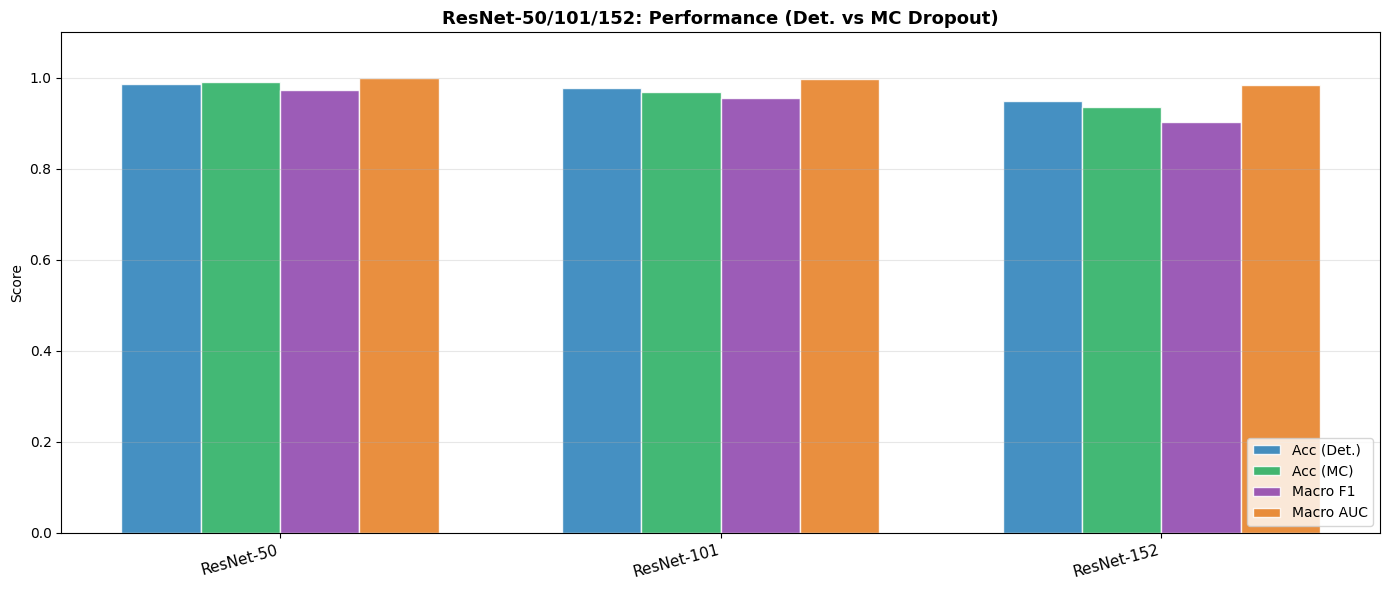

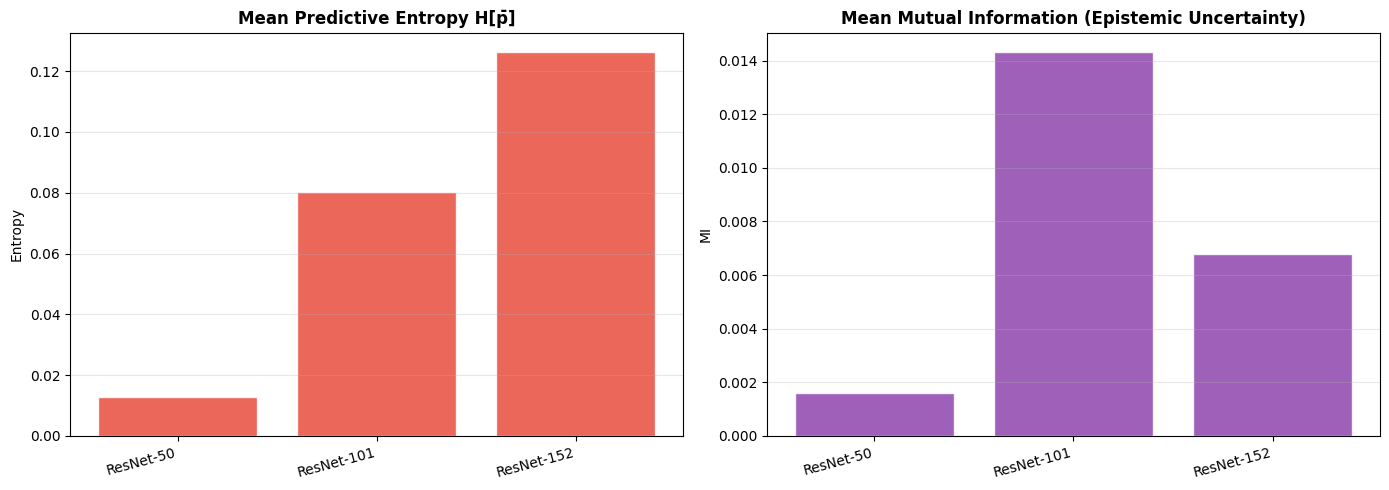

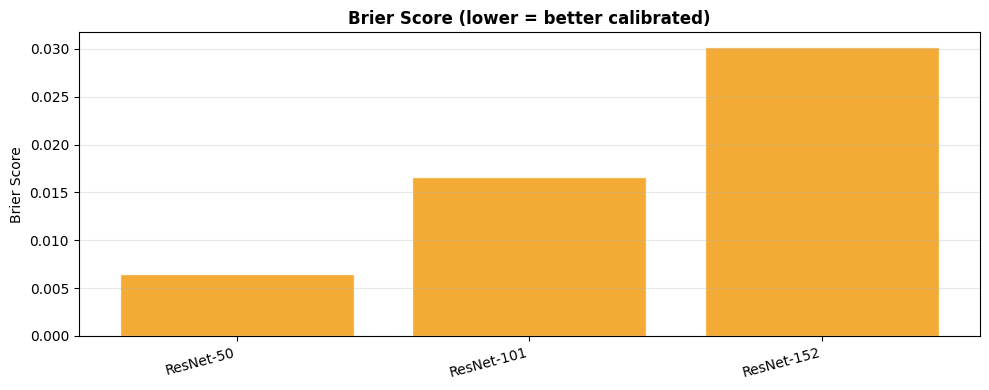

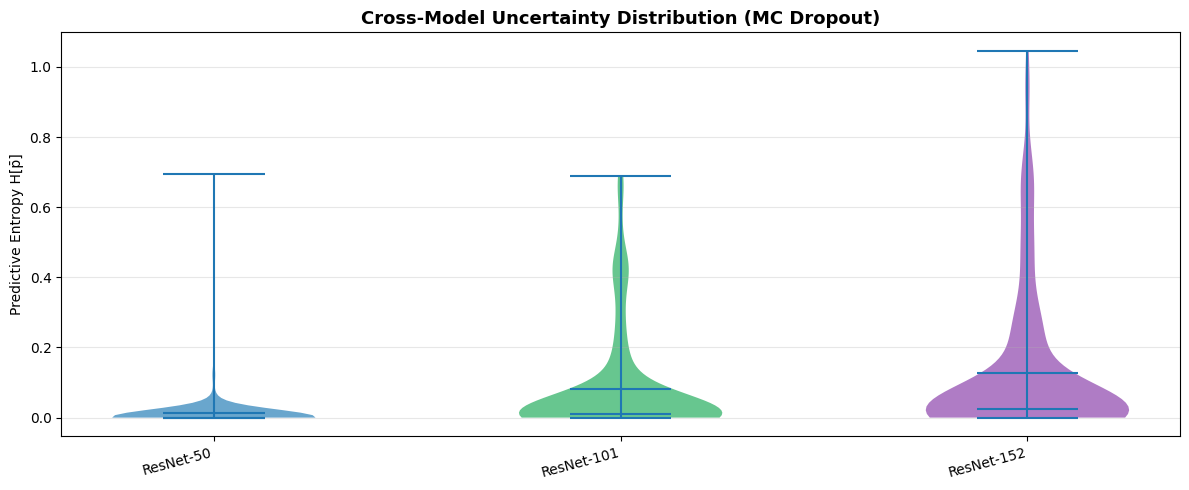

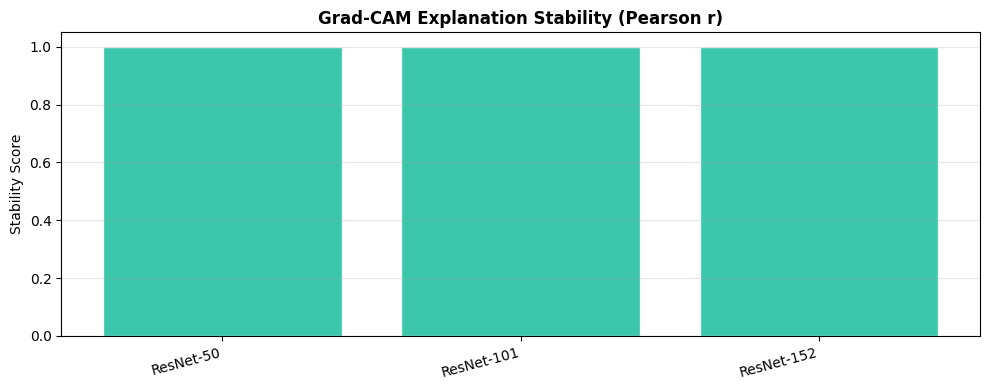

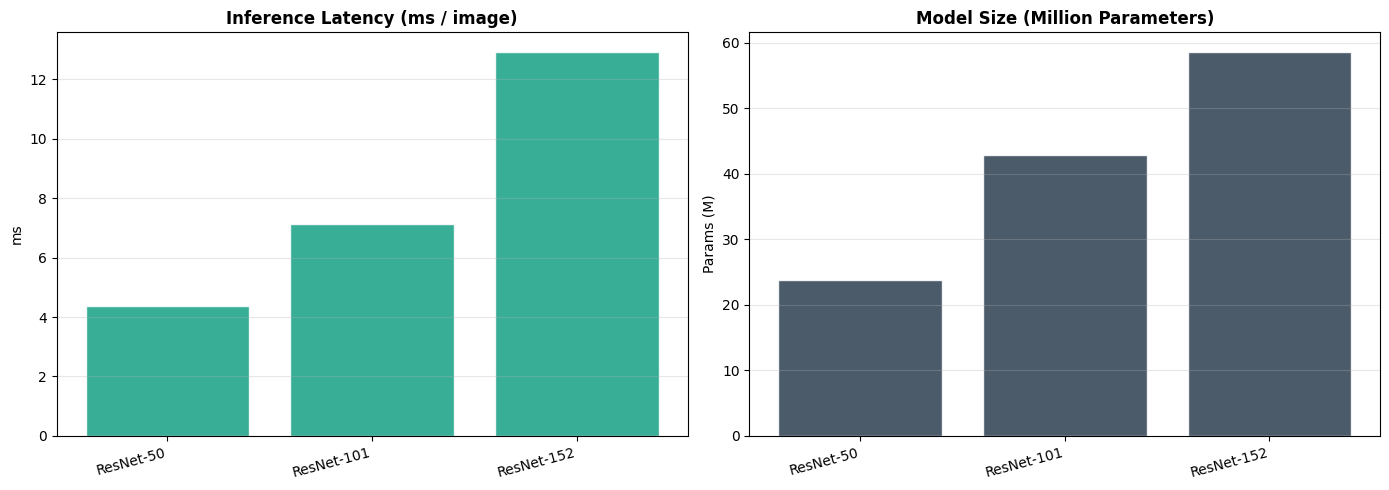

In [15]:
# ==========================================
# CELL 15: CROSS-MODEL COMPARISON CHARTS
# ==========================================

model_names = df['Model'].tolist()
x     = np.arange(len(model_names))
bar_w = 0.18
palette = ['#2980b9','#27ae60','#8e44ad','#e67e22']

# ---- Chart 1: Accuracy / F1 / AUC / MC Accuracy ----
fig, ax = plt.subplots(figsize=(14, 6))
metrics = [('accuracy','Acc (Det.)'),('mc_accuracy','Acc (MC)'),
           ('macro_f1','Macro F1'),('macro_auc','Macro AUC')]
for j, (col, label) in enumerate(metrics):
    ax.bar(x + j*bar_w, df[col], bar_w, label=label,
           color=palette[j], alpha=0.87, edgecolor='white')
ax.set_xticks(x + bar_w*1.5)
ax.set_xticklabels(model_names, rotation=15, ha='right', fontsize=11)
ax.set_ylim(0, 1.10)
ax.set_ylabel('Score'); ax.set_title('ResNet-50/101/152: Performance (Det. vs MC Dropout)',
                                     fontsize=13, fontweight='bold')
ax.legend(loc='lower right'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# ---- Chart 2: Predictive Entropy + MI ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(model_names, df['mean_entropy'], color='#e74c3c', alpha=0.85, edgecolor='white')
axes[0].set_title('Mean Predictive Entropy H[p̄]', fontweight='bold')
axes[0].set_ylabel('Entropy'); axes[0].grid(axis='y', alpha=0.3)
axes[0].set_xticklabels(model_names, rotation=15, ha='right')
axes[1].bar(model_names, df['mean_mi'], color='#8e44ad', alpha=0.85, edgecolor='white')
axes[1].set_title('Mean Mutual Information (Epistemic Uncertainty)', fontweight='bold')
axes[1].set_ylabel('MI'); axes[1].grid(axis='y', alpha=0.3)
axes[1].set_xticklabels(model_names, rotation=15, ha='right')
plt.tight_layout(); plt.show()

# ---- Chart 3: Brier Score ----
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(model_names, df['mean_brier'], color='#f39c12', alpha=0.85, edgecolor='white')
ax.set_title('Brier Score (lower = better calibrated)', fontweight='bold')
ax.set_ylabel('Brier Score'); ax.grid(axis='y', alpha=0.3)
ax.set_xticklabels(model_names, rotation=15, ha='right')
plt.tight_layout(); plt.show()

# ---- Chart 4: Entropy violin across models ----
plot_entropy_violin(all_entropy)

# ---- Chart 5: Grad-CAM Stability ----
plot_stability(all_stability)

# ---- Chart 6: Latency + Parameters ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(model_names, df['latency_ms'], color='#16a085', alpha=0.85, edgecolor='white')
axes[0].set_title('Inference Latency (ms / image)', fontweight='bold')
axes[0].set_ylabel('ms'); axes[0].grid(axis='y', alpha=0.3)
axes[0].set_xticklabels(model_names, rotation=15, ha='right')
axes[1].bar(model_names, df['params_M'], color='#2c3e50', alpha=0.85, edgecolor='white')
axes[1].set_title('Model Size (Million Parameters)', fontweight='bold')
axes[1].set_ylabel('Params (M)'); axes[1].grid(axis='y', alpha=0.3)
axes[1].set_xticklabels(model_names, rotation=15, ha='right')
plt.tight_layout(); plt.show()

Cross-Model Uncertainty–XAI Correlation Heatmaps

Metric: Saliency Diffuseness (1 - Gini)


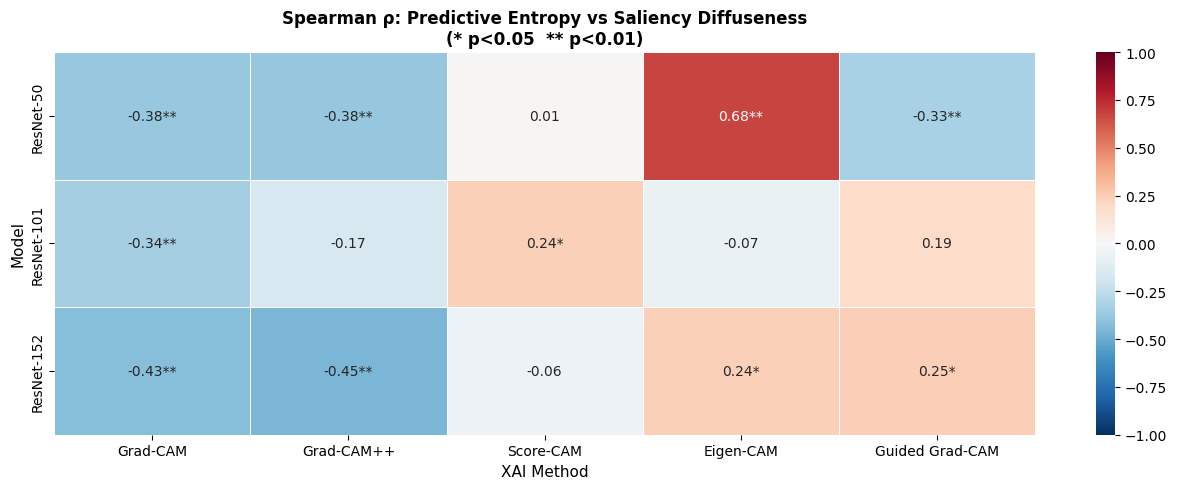


Metric: Saliency Entropy


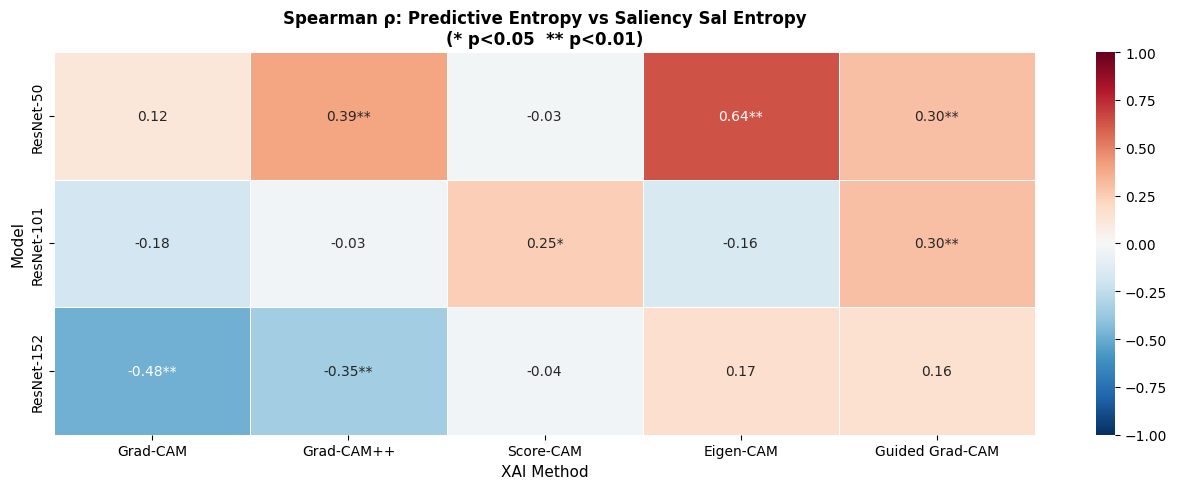


Metric: Effective Mass Fraction


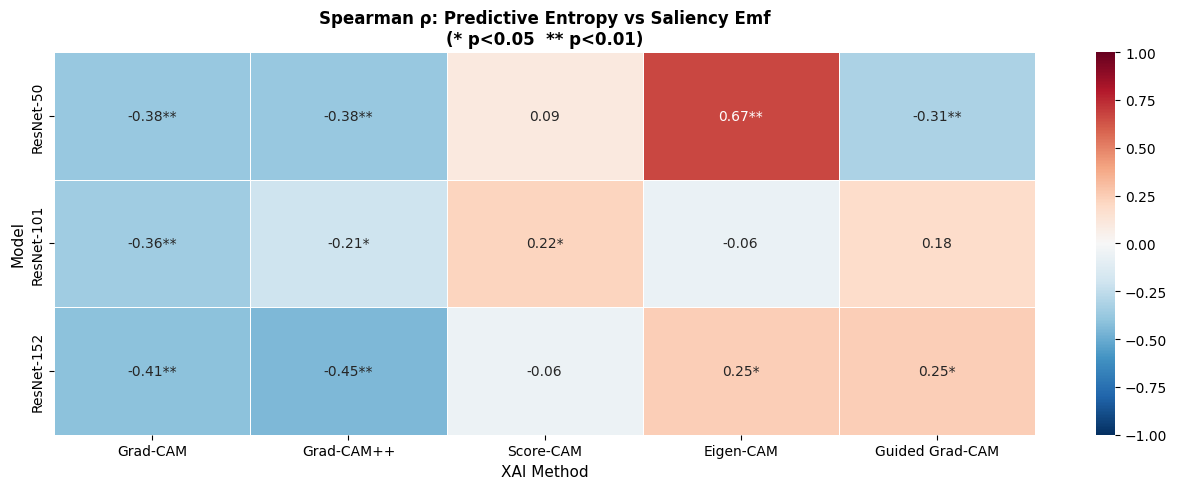


SUMMARY: Mean |ρ| per Model × XAI Method (Diffuseness metric)
             Grad-CAM Grad-CAM++  Score-CAM  Eigen-CAM Guided Grad-CAM
Model                                                                 
ResNet-50   -0.383 **  -0.384 **  +0.008 ns  +0.676 **       -0.326 **
ResNet-101  -0.338 **  -0.171 ns   +0.235 *  -0.065 ns       +0.188 ns
ResNet-152  -0.426 **  -0.454 **  -0.060 ns   +0.238 *        +0.246 *

ρ: Spearman correlation between entropy H[p̄] and saliency diffuseness
Positive ρ → higher uncertainty aligns with more diffuse saliency maps


In [16]:
# ==========================================
# CELL 16: CROSS-MODEL UNCERTAINTY–XAI HEATMAPS
#
# One heatmap per spatial metric:
#   rows = models, columns = XAI methods
#   cell = Spearman ρ (* p<0.05, ** p<0.01)
#
# Interpretation guide:
#   ρ > 0 → higher entropy → more diffuse map (expected)
#   ρ < 0 → higher entropy → more focal map (counter-intuitive)
#   |ρ| near 0 → no relationship between uncertainty and XAI
# ==========================================

print("Cross-Model Uncertainty–XAI Correlation Heatmaps")
print("=" * 65)

for metric_label, metric_key in [
    ('Saliency Diffuseness (1 - Gini)', 'diffuseness'),
    ('Saliency Entropy',                'sal_entropy'),
    ('Effective Mass Fraction',         'emf'),
]:
    print(f"\nMetric: {metric_label}")
    plot_correlation_heatmap(all_corr, metric=metric_key)

# ---- Summary table ----
print("\nSUMMARY: Mean |ρ| per Model × XAI Method (Diffuseness metric)")
xai_names = ['Grad-CAM', 'Grad-CAM++', 'Score-CAM', 'Eigen-CAM', 'Guided Grad-CAM']
rows = []
for mn in all_corr:
    row = {'Model': mn}
    for xn in xai_names:
        try:
            rho, pval = all_corr[mn][xn]['diffuseness']
            sig = '**' if pval < 0.01 else ('*' if pval < 0.05 else 'ns')
            row[xn] = f"{rho:+.3f} {sig}"
        except Exception:
            row[xn] = 'N/A'
    rows.append(row)
df_corr_summary = pd.DataFrame(rows).set_index('Model')
print(df_corr_summary.to_string())
print("\nρ: Spearman correlation between entropy H[p̄] and saliency diffuseness")
print("Positive ρ → higher uncertainty aligns with more diffuse saliency maps")

In [17]:
# ==========================================
# CELL 17: FINAL RANKING & RECOMMENDATION
# Composite score balances classification
# performance AND uncertainty quality:
#
# composite = 30% Accuracy
#           + 20% Macro F1
#           + 20% Macro AUC
#           + 10% Calibration  (1 - norm_brier)
#           + 10% Speed        (1 - norm_latency)
#           + 10% Stability
# ==========================================

df['norm_brier']    = (df['mean_brier'] - df['mean_brier'].min()) / \
                      (df['mean_brier'].max() - df['mean_brier'].min() + 1e-9)
df['norm_latency']  = (df['latency_ms'] - df['latency_ms'].min()) / \
                      (df['latency_ms'].max() - df['latency_ms'].min() + 1e-9)
df['norm_stability']= (df['stability']  - df['stability'].min())  / \
                      (df['stability'].max()  - df['stability'].min() + 1e-9)

df['composite'] = (
    0.30 * df['accuracy']             +
    0.20 * df['macro_f1']             +
    0.20 * df['macro_auc']            +
    0.10 * (1 - df['norm_brier'])     +
    0.10 * (1 - df['norm_latency'])   +
    0.10 * df['norm_stability']
).round(4)

df_rank = df[['Model','accuracy','mc_accuracy','macro_f1','macro_auc',
              'mean_entropy','mean_brier','latency_ms','stability','composite']]\
            .sort_values('composite', ascending=False).reset_index(drop=True)
df_rank.index += 1
df_rank.index.name = 'Rank'

print("\n" + "="*100)
print("  FINAL RANKING — Uncertainty-Aware ResNet-50/101/152")
print("  IQ-OTH/NCCD Lung Cancer Detection")
print("="*100)
print(df_rank.round(4).to_string())
print("\nComposite = 30% Acc + 20% F1 + 20% AUC + 10% Calibration + 10% Speed + 10% Stability")

winner = df_rank.iloc[0]
print("\n" + "-"*100)
print(f"  RECOMMENDED MODEL : {winner['Model']}")
print(f"  Det. Accuracy     : {winner['accuracy']:.4f}")
print(f"  MC Accuracy       : {winner['mc_accuracy']:.4f}")
print(f"  Macro F1          : {winner['macro_f1']:.4f}")
print(f"  Macro AUC         : {winner['macro_auc']:.4f}")
print(f"  Mean Entropy      : {winner['mean_entropy']:.4f}")
print(f"  Brier Score       : {winner['mean_brier']:.4f}")
print(f"  Latency           : {winner['latency_ms']:.2f} ms/image")
print("-"*100)


  FINAL RANKING — Uncertainty-Aware ResNet-50/101/152
  IQ-OTH/NCCD Lung Cancer Detection
           Model  accuracy  mc_accuracy  macro_f1  macro_auc  mean_entropy  mean_brier  latency_ms  stability  composite
Rank                                                                                                                    
1      ResNet-50    0.9864       0.9909    0.9735     0.9996        0.0129      0.0064      4.3580        1.0     0.9327
2     ResNet-101    0.9773       0.9682    0.9556     0.9970        0.0802      0.0166      7.1260        1.0     0.8086
3     ResNet-152    0.9500       0.9364    0.9030     0.9844        0.1264      0.0302     12.9304        1.0     0.7625

Composite = 30% Acc + 20% F1 + 20% AUC + 10% Calibration + 10% Speed + 10% Stability

----------------------------------------------------------------------------------------------------
  RECOMMENDED MODEL : ResNet-50
  Det. Accuracy     : 0.9864
  MC Accuracy       : 0.9909
  Macro F1          : 0.97

In [18]:
# ==========================================
# CELL 18: SAVE ALL RESULTS TO GOOGLE DRIVE
# ==========================================
base_path = '/content/drive/My Drive/Kaggle/IQ-OTH-NCCD/'

# Classification + uncertainty metrics
df_rank.to_csv(base_path + 'resnet_uncertainty_ranking.csv')
print(f"Ranking saved to: {base_path}resnet_uncertainty_ranking.csv")

# Uncertainty–XAI correlation summary
df_corr_summary.to_csv(base_path + 'resnet_uncertainty_xai_correlation.csv')
print(f"Correlation table saved to: {base_path}resnet_uncertainty_xai_correlation.csv")

print("\nAll results saved.")


Ranking saved to: /content/drive/My Drive/Kaggle/IQ-OTH-NCCD/resnet_uncertainty_ranking.csv
Correlation table saved to: /content/drive/My Drive/Kaggle/IQ-OTH-NCCD/resnet_uncertainty_xai_correlation.csv

All results saved.
